Accuracy score is: 1.0
Cross Validation score is: 1.0


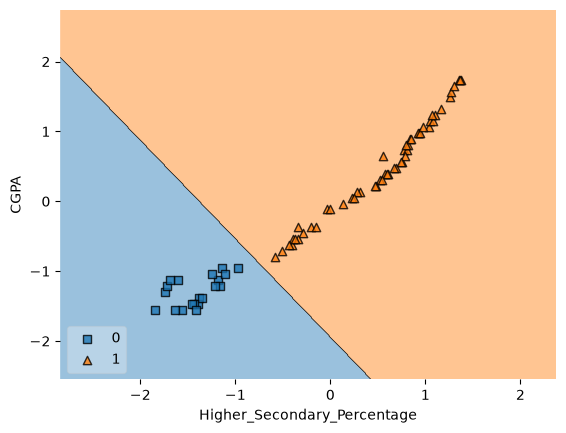

'\n\nwith open("Stud.pkl","wb") as write:\n    pickle.dump(logrg,write)\n\n'

In [2]:
# This code represnets an example of a ML workflow. It predicts wheteher a student will be apponited in a company based on his GPA.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from mlxtend.plotting import plot_decision_regions
import pickle

scaler = StandardScaler()
label = LabelEncoder()
logrg = LogisticRegression()

data = pd.read_csv("C:\\Users\\sulem\\OneDrive\\Desktop\\Codes\\ML\\Datasets\\Job.csv")
dataset = pd.DataFrame(data)

dataset["Status"] = label.fit_transform(dataset["Placement_Status"])
dataset.drop("Placement_Status", axis=1 , inplace=True)
dataset.drop("Secondary_Percentage", axis=1 , inplace=True)
dataset.drop_duplicates()

# print(dataset.shape)

# plt.scatter(dataset["Higher_Secondary_Percentage"],dataset["CGPA"], c=dataset["Status"])
# plt.show()
# print(dataset.head())

x = dataset.iloc[: , : -1]
y = dataset.iloc[: , -1]

# print(x.head())
# print(y.head())
# print(x.shape)
# print(y.shape)

trainx , testx, trainy , testy = train_test_split(x,y, test_size=0.3, random_state=3)

# print(trainx.head())
# print(trainx.shape)
# print(testx.head())
# print(trainy.head())
# print(testy.head())
# print(testy.shape)

trainx = scaler.fit_transform(trainx)
testx = scaler.transform(testx)

# Now That the dataframe has been converted into a numpy array, we wont be needing the .head() function.

# print(trainx)
# print(trainy)

# Model Training by Logistic Regression

logrg.fit(trainx,trainy)
predy = logrg.predict(testx)

# Now we will see our accuracy score by comapring the values of our testy with predy.

print("Accuracy score is:",accuracy_score(testy, predy))
print("Cross Validation score is:",np.mean(cross_val_score(estimator= logrg, X=x, y=y,  scoring="accuracy", cv =10)))

# Now we will show logistic regression line on 2D format

plot_decision_regions(trainx, trainy.values, clf = logrg, legend=3)
plt.xlabel(dataset.columns[0]) # Use original column names for labels
plt.ylabel(dataset.columns[1])
plt.show()

# clf = classifier
# values indicate trainy is a numpy array. trainx was already a numpy array due to standardization with scaler function.

# Making a file out of logrg

'''

with open("Stud.pkl","wb") as write:
    pickle.dump(logrg,write)
    
'''